# 2026 Annual report

In [2]:
%load_ext autoreload
%autoreload 2

In [ ]:
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pytz
import seaborn as sns

from usagestats import visual
from usagestats.bookingdb import BookingDB

folder = Path(
    "/run/user/1000/gvfs/smb-share:server=istore,share=microscopy_group_share,user=jeromeb/Admin/Usage Stats/2026"
)
export = folder / "report"
export.mkdir(parents=True, exist_ok=True)
db_file = folder / "bookings2.db"
local_tz = pytz.timezone("Europe/London")
start_date = datetime.fromisoformat("2025-11-01").replace(tzinfo=local_tz)
num_weeks = 52
end_date = start_date + timedelta(weeks=num_weeks)  # iso-format data yyyy-mm-dd
drop_bookings_type = ["service", "maintenance", "training"]
drop_instrument = ["Analysis PC1", "Analysis PC2", "Analysis PC3", "Analysis PC4"]

booking_types = ["default", "service", "maintenance", "training"]
divisions = [
    "Unknown",
    "Cell Biology",
    "Neurobiology",
    "PNAC",
    "Structural Studies",
    "University",
]


In [ ]:
groups = pd.read_csv(folder / "groups.csv")
users = pd.read_csv(folder / "users.csv")
training = pd.read_csv(folder / "training.csv")
calendars = pd.read_csv(folder / "calendars.csv")

# get a cookie from the curl command copied from firefox dev tools and save it in a cookie.txt file
with open("cookie.txt", "r") as f:
    curl_str = f.read()

# check that the calendars url are uniques
assert calendars["url"].is_unique, "Calendar URLs are not unique!"

known_users = users
print(
    f"There are {len(calendars)} calendars for {calendars['instrument'].nunique()} instruments."
)
print(f"There are {len(users)} known users.")
print(f"There are {len(groups)} groups.")

# Load all calendars in the database
Path(db_file).unlink(True)
with BookingDB(db_file, curl_str=curl_str) as db:
    db.create_calendars_from_df(calendars)
    db.create_instruments()
    db.create_booking_types(booking_types)
    db.create_division(divisions)
    db.create_groups(groups)
    df, duplicates = db.create_events(known_users)

Use the training record to populate missing people

In [ ]:
# Load all users
with BookingDB(db_file) as db:
    users = db.get_unique_users_in_range(start_date, end_date)

# Get users with no groups
users_no_group = users[users["division"].str.contains("Unknow")][
    ["id", "email", "name"]
].reset_index(drop=True)

# Load and format training csv file
training = pd.read_csv(folder / "training.csv")
training = training[~training["Email"].isna()]
training = training[~training["Group"].isna()]
training["email"] = training["Email"]
training["group"] = training["Group"].apply(lambda x: x.split(" ")[-1])
training["id"] = training["email"].apply(lambda x: x.split("@")[0])
training = training[["id", "group"]].drop_duplicates("id").reset_index(drop=True)

new_users = pd.merge(users_no_group, training, how="inner", on="id")

with BookingDB(db_file) as db:
    db.update_users_group_from_df(new_users)

# Check the remaining unknown users
with BookingDB(db_file) as db:
    unique_users = db.get_unique_users_in_range(start_date, end_date)
unique_users[unique_users["group"] == "Unknown"]  # .to_csv(folder/"new_new_user.csv")

In [ ]:
new_new_users = pd.read_csv(folder / "new_new_user.csv")
with BookingDB(db_file) as db:
    db.update_users_group_from_df(new_new_users)
with BookingDB(db_file) as db:
    unique_users = db.get_unique_users_in_range(start_date, end_date)
print("Unknown users")
unique_users[unique_users["group"] == "Unknown"]

## Report

In [12]:
import matplotlib

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

sns.set_context("paper")
sns.set_style("whitegrid")

In [13]:
with BookingDB(db_file) as db:
    bookings = db.get_events_in_range(start_date, end_date)


# fix booking types
def get_type_from_str(x):
    types = {
        "serv": "service",
        "maint": "maintenance",
        "train": "training",
        "maintenace": "maintenance",
    }
    for y in types:
        if x.lower().find(y) >= 0:
            return types[y]
    return "default"


bookings["type"] = [get_type_from_str(x) for x in bookings["subject"]]

### Booking by type

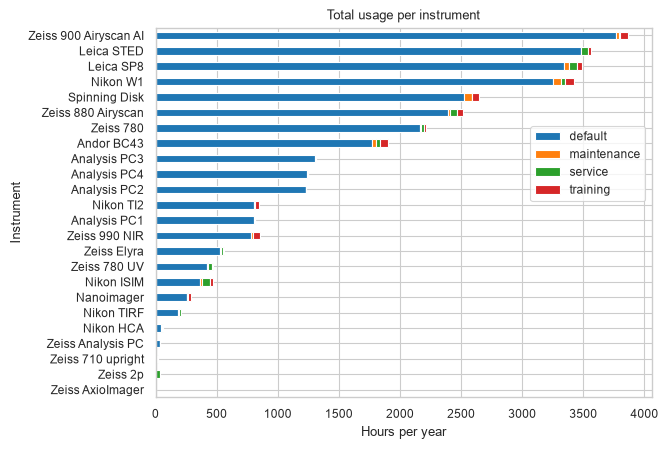

In [14]:
hours_insts = (
    bookings.groupby(["type", "instrument"], as_index=False)
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .pivot(index="instrument", values="hours", columns="type")
    .fillna(0)
    .sort_values("default")
)

hours_insts.plot(kind="barh", stacked=True)
plt.xlabel("Hours per year")
plt.ylabel("Instrument")
plt.legend(bbox_to_anchor=(1, 0.75))
plt.title("Total usage per instrument")
plt.savefig(folder / "per_type.pdf", pad_inches=1.2, bbox_inches="tight")

(
    bookings.groupby(["type", "instrument"], as_index=False)
    .agg(hours=pd.NamedAgg(column="hours", aggfunc="sum"))
    .pivot_table(index="instrument", values="hours", columns="type", margins=True)
    .fillna(0)
    .sort_values("default")
    .to_csv(folder / "per_type.csv")
)


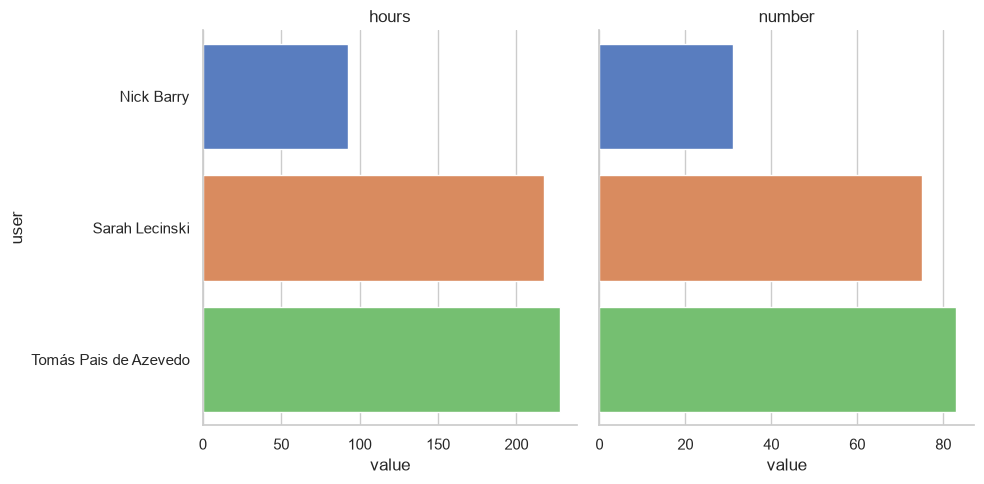

In [82]:
trng = bookings[bookings["type"]=="training"].groupby("user").agg(hours=pd.NamedAgg("hours","sum"),number=pd.NamedAgg("hours","count")).reset_index().melt(value_vars=["hours","number"],id_vars="user")
trng = trng[trng["user"].isin(["Nick Barry","Sarah Lecinski","Tomás Pais de Azevedo"])]
g = sns.catplot(trng,y="user",x="value",col="variable",kind="bar",hue="user",sharex=False)
g.set_titles(template="{col_name}")
plt.savefig(export/"trainer.pdf")
bookings[bookings["type"]=="training"].groupby("user").agg(hours=pd.NamedAgg("hours","sum"),number=pd.NamedAgg("hours","count")).reset_index().to_csv(export/"trainer.csv")


### Filtering

In [15]:
# excludes special bookings
bookings_flt = bookings[~bookings["type"].isin(drop_bookings_type)]
# excludes instruments
bookings_flt = bookings_flt[~bookings_flt["instrument"].isin(drop_instrument)]
# exclude unknownbookings = bookings[bookings["group"] != "Unknown"]
bookings_flt = bookings_flt[bookings_flt["division"] != "Unknown"]

In [94]:
bookings.agg(hours=pd.NamedAgg("hours","sum"),num_booking=pd.NamedAgg("hours","count"),num_users=pd.NamedAgg("user","nunique"),num_group=pd.NamedAgg("group","nunique"))

,hours,user,group
hours,32088.25,NaN,NaN
num_booking,8538.00,NaN,NaN
num_users,NaN,200.0,NaN
num_group,NaN,NaN,49.0


In [ ]:
info_str = visual.get_title_str(bookings_flt, start_date, end_date)
with open(export / "info.txt", "w") as f:
    f.write("Filtered data")
    f.write(info_str)

### Usage per category

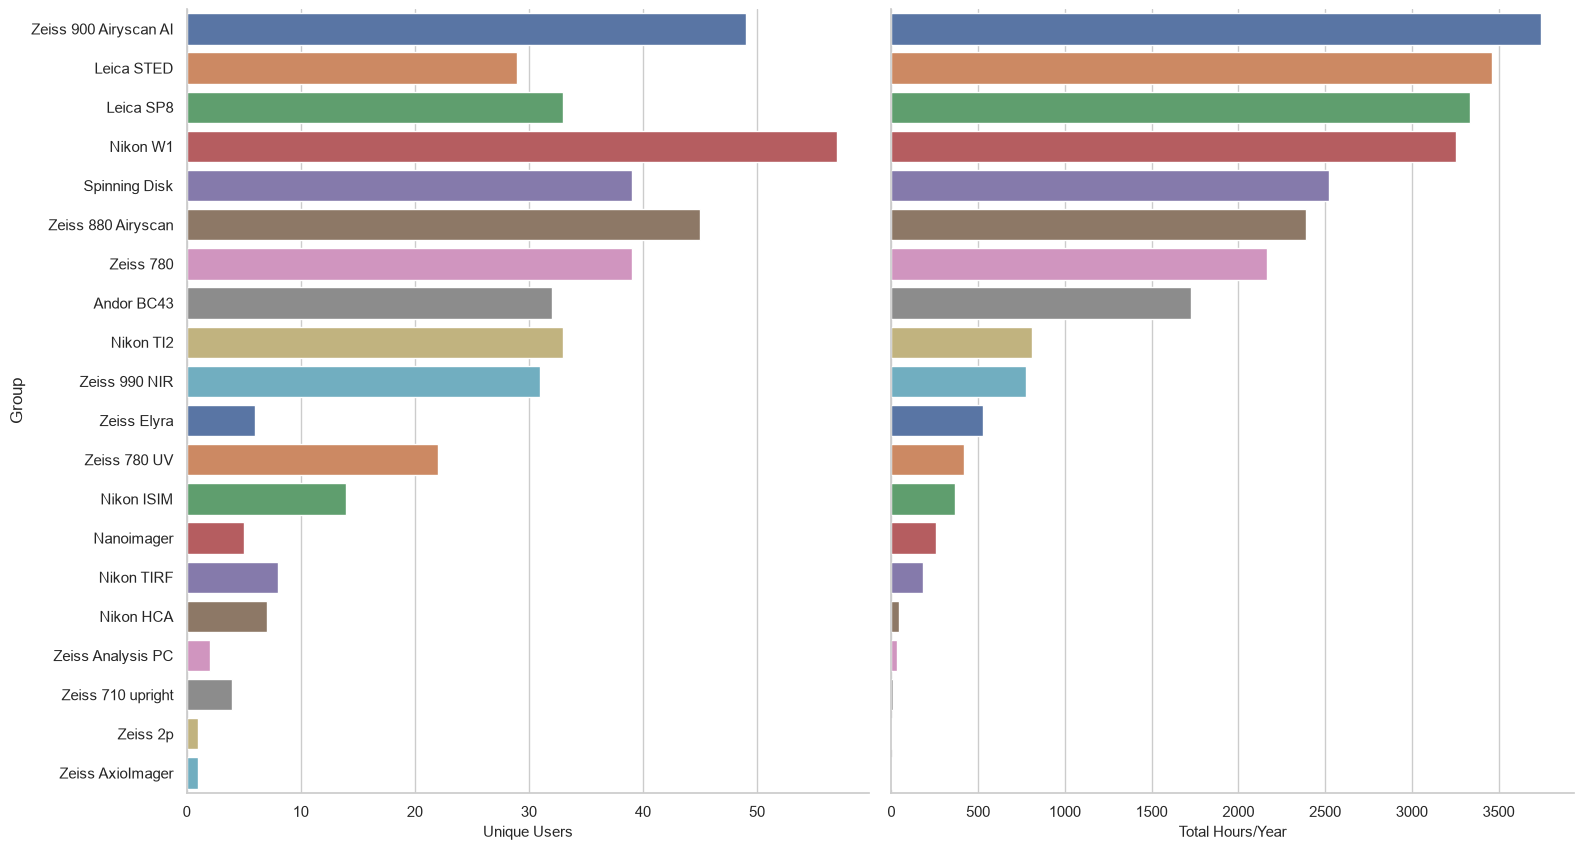

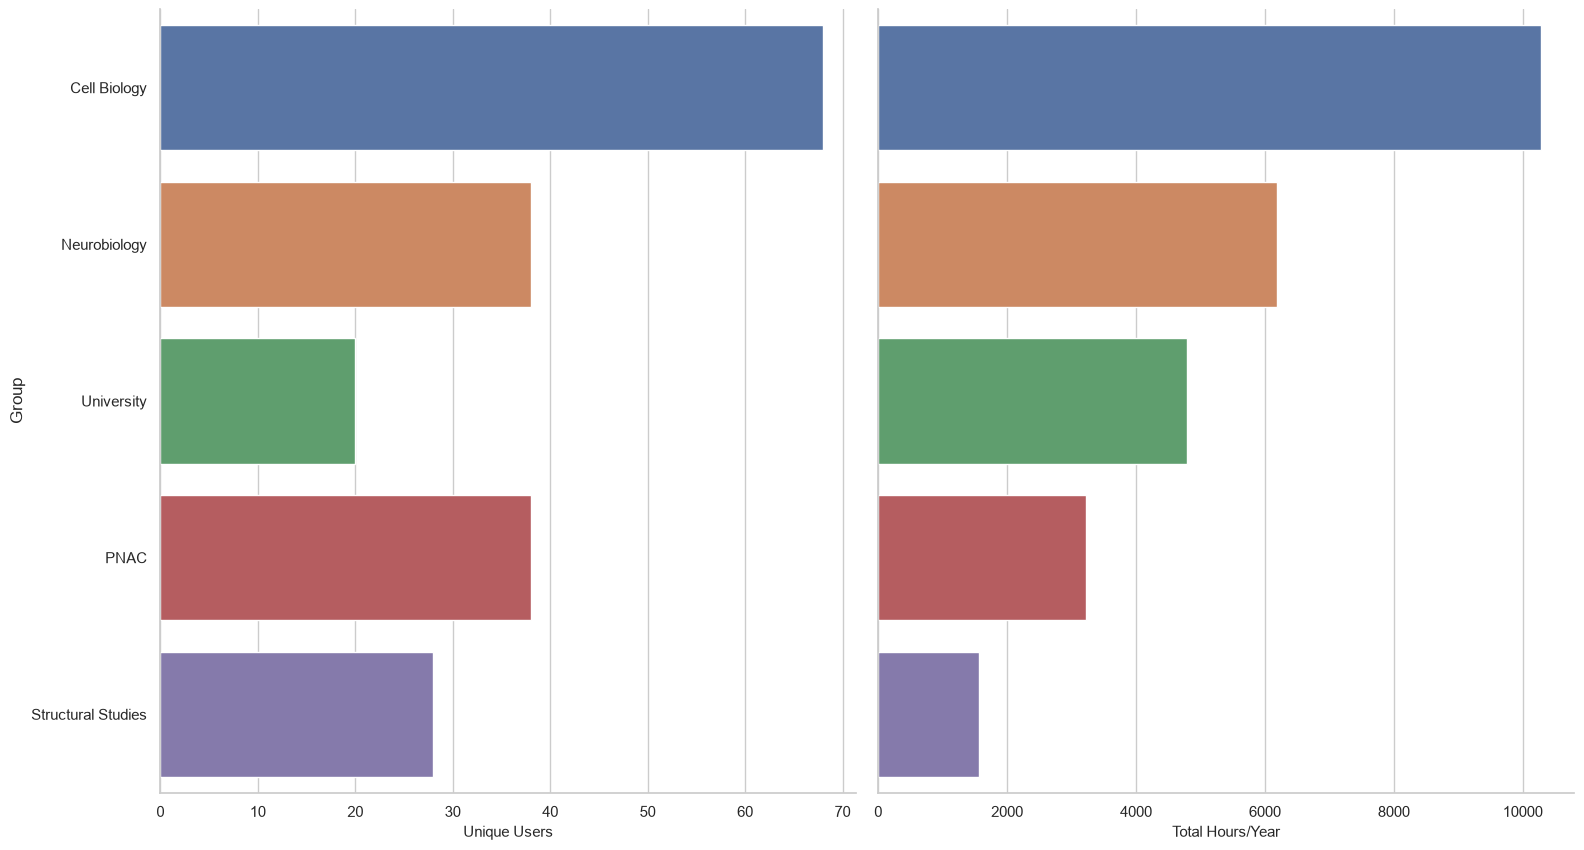

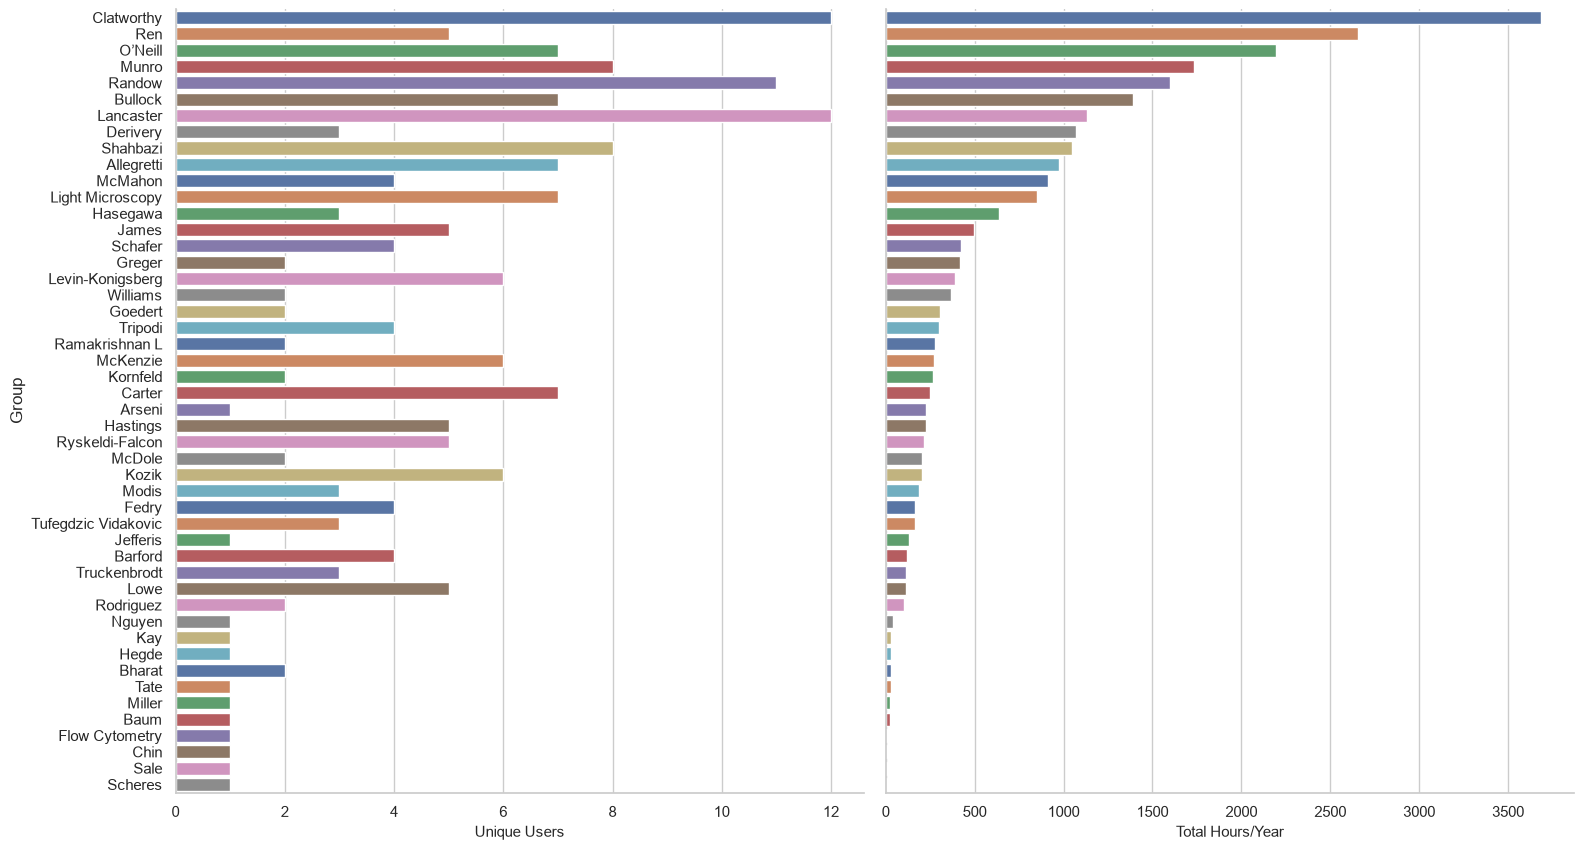

In [99]:
def plot_per_category(bookings, cat):
    usr = (
        bookings.groupby(cat)["user"]
        .nunique()
        .to_frame()
        .rename(columns={"user": "Unique Users"})
    )

    hrs = (
        bookings.groupby(cat)["hours"]
        .sum()
        .to_frame()
        .sort_values("hours", ascending=False)
        .rename(columns={"hours": "Total Hours"})
    )

    # Merge, sort by primary metric, and melt for Seaborn
    per_cat = (
        usr.merge(hrs, left_index=True, right_index=True)
        .sort_values("Total Hours", ascending=False)
        .reset_index()
        .melt(id_vars=[cat], var_name="Metric", value_name="Value")
    )

    # 3. Enhanced catplot
    g = sns.catplot(
        data=per_cat,
        kind="bar",
        x="Value",
        y=cat,
        hue=cat,
        palette="deep",  
        col="Metric",
        height=10,
        aspect=0.8,
        sharex=False,  
    )

    # 4. Polish titles and labels
    g.set_titles(template="")
    g.set_axis_labels("Usage Value", "Group")
    g.figure.subplots_adjust(top=0.85)
    x_labels = ["Unique Users", "Total Hours/Year"]
    for ax, label in zip(g.axes.flat, x_labels):
        ax.set_xlabel(label, fontsize=11)

    return g.figure, per_cat.pivot_table(values="Value", index=cat, columns="Metric", margins=True)


for category in ["instrument","division","group"]:
    fig, res = plot_per_category(bookings_flt, category)
    res.to_csv(export / f"per_{category}.csv")
    fig.savefig(export / f"per_{category}.pdf", pad_inches=1.1, bbox_inches="tight")
    

### Matrix

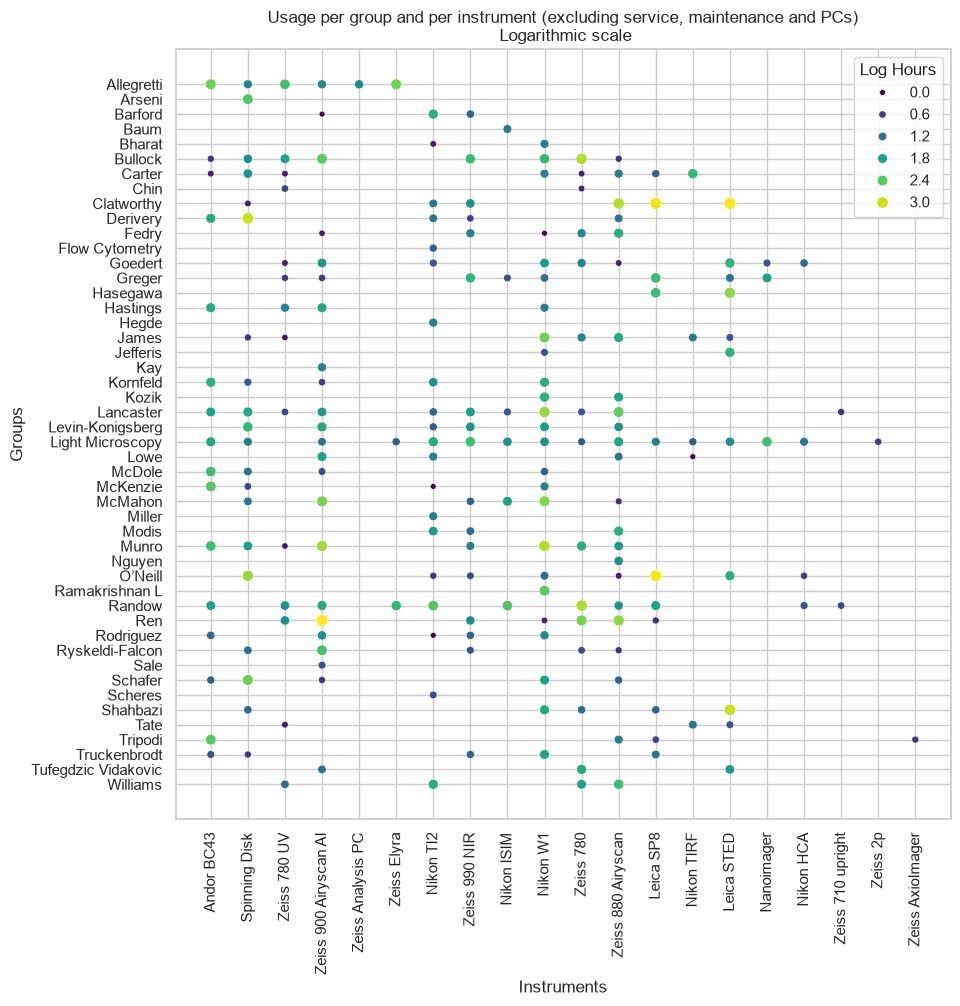

In [ ]:
import math

# bookings.groupby(['Group','Instrument'], as_index=False)['Hours'].agg('sum').pivot(index="Group",columns="Instrument",values='Hours').fillna(0).to_csv('usage-per-group-per-instrument.csv')
f, x = plt.subplots(figsize=(10, 10))
tmp = bookings_flt.groupby(["group", "instrument"], as_index=False)["hours"].agg("sum")
tmp["hours"] = [math.log10(x) for x in tmp["hours"]]
cmap = sns.color_palette("viridis", as_cmap=True)
# order = tmp.groupby('Group').agg(time=('Hours',sum)).sort_values('time',ascending=False).index.values
sns.scatterplot(
    data=tmp, x="instrument", y="group", size="hours", hue="hours", palette=cmap
)
plt.xticks(rotation=90)
plt.ylabel("Groups")
plt.xlabel("Instruments")
plt.title(
    "Usage per group and per instrument (excluding service, maintenance and PCs)\n Logarithmic scale"
)
plt.legend(title="Log Hours")
plt.savefig(export / "matrix.pdf", pad_inches=1.2, bbox_inches="tight")

### By users

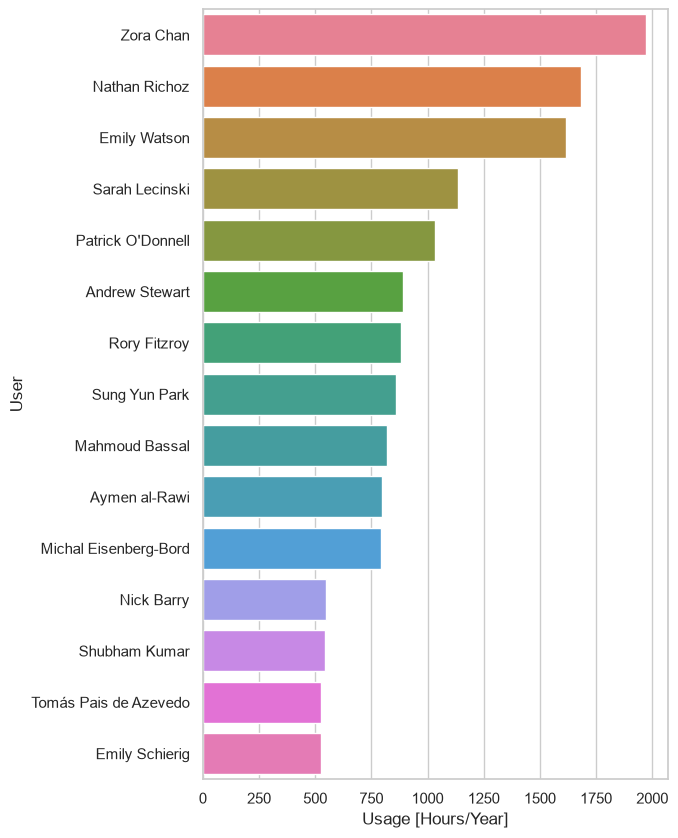

In [26]:
from usagestats import visual

top_users = (
    bookings.groupby("user")["hours"]
    .sum()
    .to_frame()
    .sort_values("hours", ascending=False)
)

f, ax = plt.subplots(figsize=(6, 10))
ax = sns.barplot(data=top_users.iloc[:15], x="hours", y="user", hue="user")
plt.xlabel("Usage [Hours/Year]")
plt.ylabel("User")
# plt.title("Number of hours per user (top 15)" + info_str)
plt.savefig(export / "winners.pdf", pad_inches=1.2, bbox_inches="tight")

### Weekly usage

In [27]:
usage = visual.weekly_usage_by_instrument(bookings_flt, start_date, end_date)

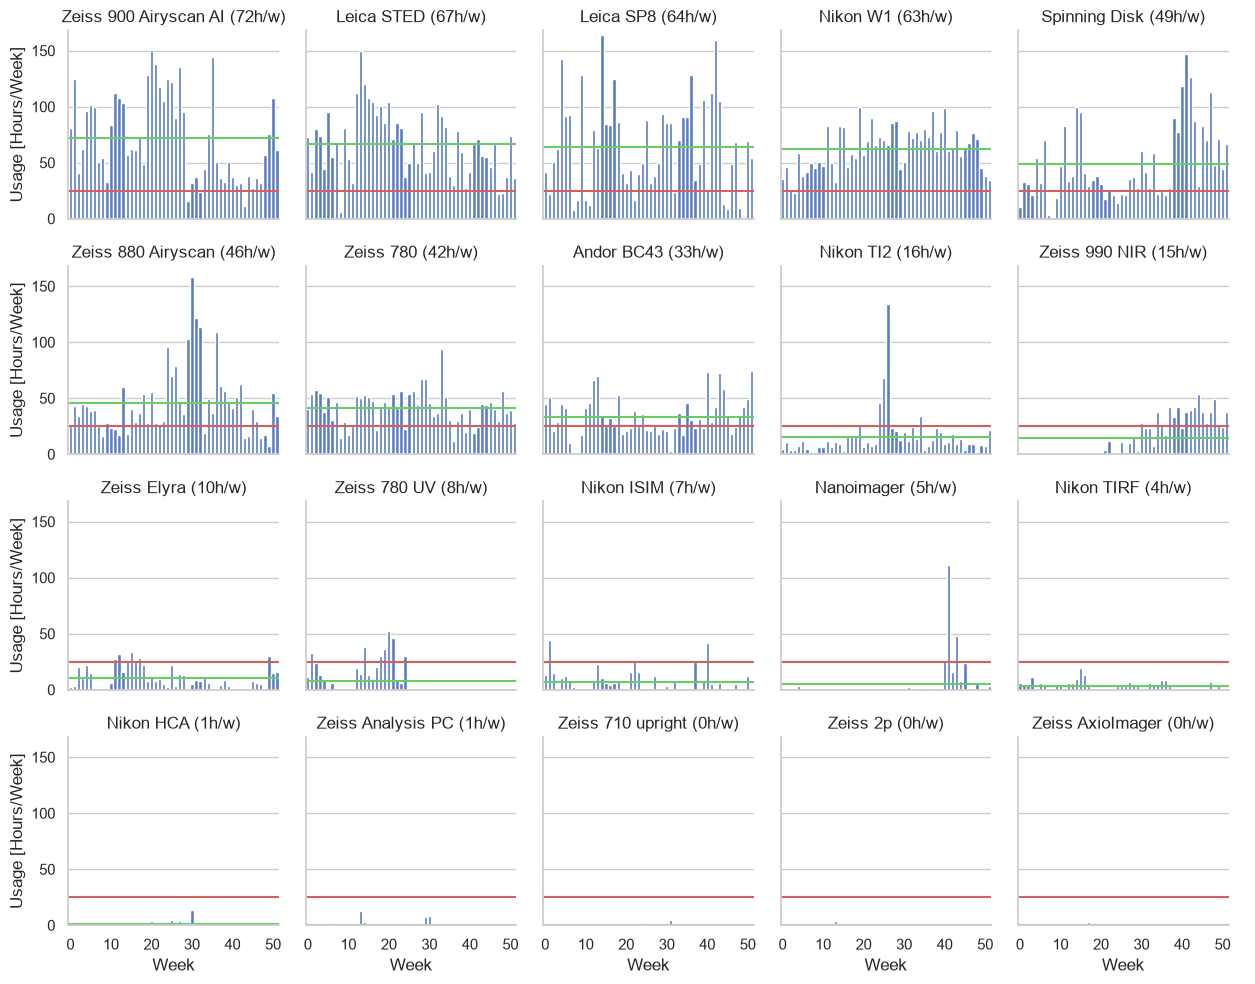

In [29]:
import numpy as np

# figure for each instruments

col_order = (
    bookings_flt.groupby("instrument")["hours"].sum().sort_values(ascending=False).index
)

g = sns.catplot(
    usage,
    kind="bar",
    x="Week",
    y="Usage",
    col="Instrument",
    col_wrap=5,
    col_order=col_order,
    height=2.5,
)
g.set_titles(template="{col_name}")
averages = usage.groupby("Instrument")["Usage"].agg(["mean"])
avg_global = usage["Usage"].mean()

for k, a in enumerate(g.axes):
    mic = a.get_title()
    avg = averages["mean"][mic]
    a.set_title(f"{mic} ({avg:.0f}h/w)")
    # a.text(15,130,f'average:{avg:.0f}h/w')
    # a.set_subtitle(f'average:{avg:.0f}h/w')
    a.axhline(avg_global, color="r", linestyle="-")
    a.axhline(avg, color="g", linestyle="-")
    a.set_ylabel("Usage [Hours/Week]")
    a.set_xticks(np.arange(0, num_weeks, step=10))
    a.set_xticklabels(np.arange(0, num_weeks, step=10))
    a.set_ylim([0, 24 * 7])
# plt.subplots_adjust(top=0.9)
# plt.suptitle(
#     f"Usage per week and per instrument excluding maintenance, service and training\naverage {avg_global:.0f}h/w"
# )
plt.savefig(export / "per_week.pdf")

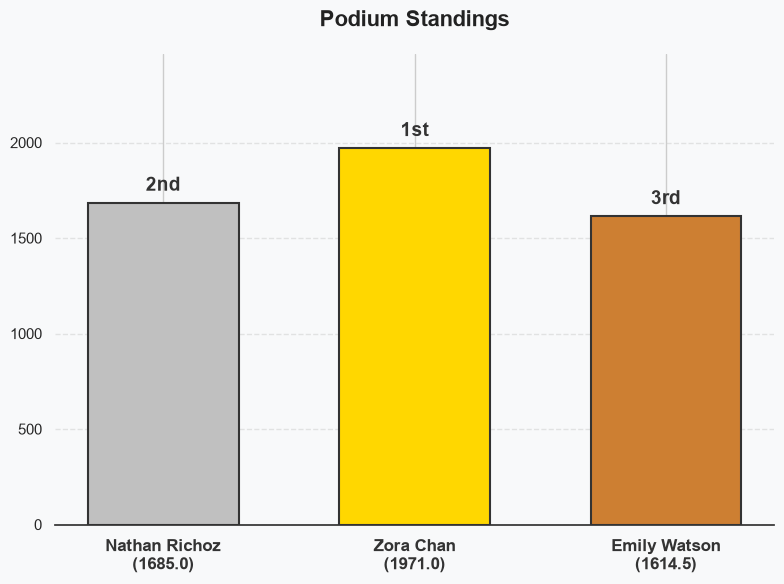

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Sample DataFrame (replace this with your actual data)
df = top_users = (
    bookings.groupby("user")["hours"]
    .sum()
    .to_frame()
    .sort_values("hours", ascending=False)
    .reset_index()
    .rename(columns={"hours": "score", "user": "name"})
    .iloc[:3]
)


# 2. Sort by the numerical column descending and take the top 3
df_top3 = df.sort_values(by="score", ascending=False).head(3).reset_index(drop=True)

# 3. Rearrange for a podium layout: [2nd Place, 1st Place, 3rd Place]
# Indices: 1 = 2nd place, 0 = 1st place, 2 = 3rd place
podium_order = [1, 0, 2]
df_podium = df_top3.iloc[podium_order].reset_index(drop=True)

# 4. Set up the figure and podium aesthetics
fig, ax = plt.subplots(figsize=(8, 6), facecolor="#f8f9fa")
ax.set_facecolor("#f8f9fa")

# Podium colors (Silver, Gold, Bronze)
colors = ["#C0C0C0", "#FFD700", "#CD7F32"]
x_positions = [1, 2, 3]

# Create bar chart
bars = ax.bar(
    x_positions,
    df_podium["score"],
    color=colors,
    width=0.6,
    edgecolor="#333333",
    linewidth=1.5,
    zorder=3,
)

# 5. Customize axes and labels
ax.set_xticks(x_positions)
# Display Name + Score on the x-axis labels
labels = [f"{row['name']}\n({row['score']})" for _, row in df_podium.iterrows()]
ax.set_xticklabels(labels, fontsize=12, fontweight="bold", color="#333333")

# Add numeric rank badges or podium step labels above the bars
podium_ranks = ["2nd", "1st", "3rd"]
for bar, rank in zip(bars, podium_ranks):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + (ax.get_ylim()[1] * 0.02),
        rank,
        ha="center",
        va="bottom",
        fontsize=14,
        fontweight="bold",
        color="#333333",
    )

# Styling clean-up
ax.set_ylim(0, df_podium["score"].max() * 1.25)  # Give headroom for text
ax.yaxis.grid(True, linestyle="--", alpha=0.5, zorder=0)
ax.set_axisbelow(True)

# Remove top and right spines for a modern look
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#333333")

plt.title("Podium Standings", fontsize=16, fontweight="bold", pad=20, color="#222222")
plt.tight_layout()

# Show the plot
plt.show()